# Fase 02 : Análisis descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [ ]:

import polars as pl
import polars.selectors as cs
from pyprojroot import here
from s_01_functions import plot_cat_function_01


<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [12]:
df_01 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_01.parquet')
df_01.glimpse()

Rows: 964947
Columns: 10
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000933', 'PRD_000201', 'PRD_000197', 'PRD_000177', 'PRD_001529', 'PRD_001525', 'PRD_000506', 'PRD_000951', 'PRD_00092

<h3 style="color:#05856d">3. Análisis descriptivo individual</h3>
<hr>

In [18]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Variables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964947
Columns: 2
$ category_name <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc       <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI

Rows: 964947
Columns: 7
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ sales_bottles     <i64> 2, 6, 7, 2, 12, 8, 7, 2, 2, 2
$ sales_dollars     <f64> 34.5, 103.5, 34.16, 17.28, 225.0, 42.0, 68.25, 34.

<h4 style="color:#05856d">3.1. Variables categóricas</h4>

Categoría del producto

In [14]:
df_01.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150281,0.15574
"""CANADIAN WHISKIES""",94301,0.097727
"""STRAIGHT BOURBON WHISKIES""",79606,0.082498
"""WHISKEY LIQUEUR""",73023,0.075676
"""100% AGAVE TEQUILA""",56097,0.058135
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1426,0.001478
"""MEZCAL""",1117,0.001158
"""SPECIAL ORDER ITEMS""",331,0.000343


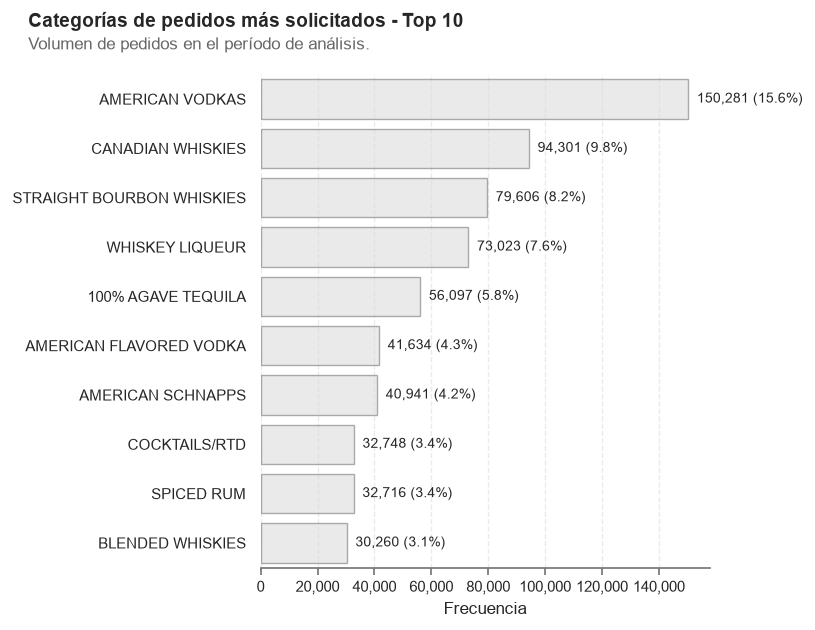

Guardado como: "s_04_01_top_10_categorias.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_01_top_10_categorias.png')

In [15]:
plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    top_param = 10,
    suptitle_param = 'Categorías de pedidos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_01_top_10_categorias.png',
    show_param = True )

Descripción del producto

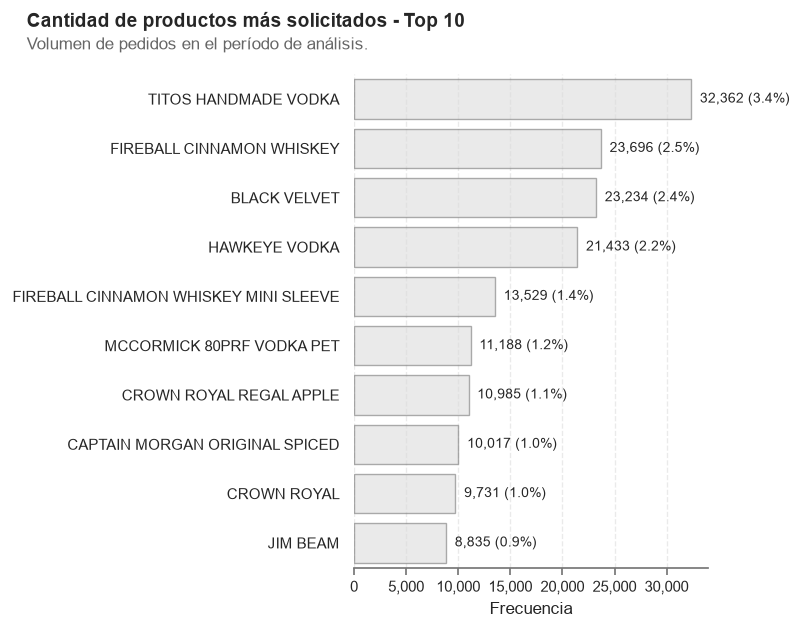

Guardado como: "s_04_02_top_10_categorias.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_02_top_10_categorias.png')

In [16]:
plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    top_param = 10,
    suptitle_param = 'Cantidad de productos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_02_top_10_categorias.png',
    show_param = True )

<h4 style="color:#05856d">3.2. Variables numéricas</h4>

In [17]:
df_01.glimpse()

Rows: 964947
Columns: 10
$ bottle_volume_ml  <f64> 750.0, 1750.0, 375.0, 50.0, 1750.0, 375.0, 375.0, 750.0, 750.0, 50.0
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no           <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on       <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack              <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ product_code      <str> 'PRD_000933', 'PRD_000201', 'PRD_000197', 'PRD_000177', 'PRD_001529', 'PRD_001525', 'PRD_000506', 'PRD_000951', 'PRD_00092